# Laborator 2

În Colab: *Runtime → Change runtime type → T4 GPU* (opțional, rețelele sunt mici și merg și pe CPU).

## Exerciții

### 1. Dataset MNIST vectorizat
Fie setul de date MNIST ce conține imagini cu cifre de la 0 la 9.

Completați metoda `__getitem__(self, idx)` a Dataset-ului astfel încât să returneze imaginea vectorizată și scalată în [0, 1] precum și label-ul asociat.

(60000, 28, 28) uint8 (60000,)
(10000, 28, 28) uint8 (10000,)
(28, 28)


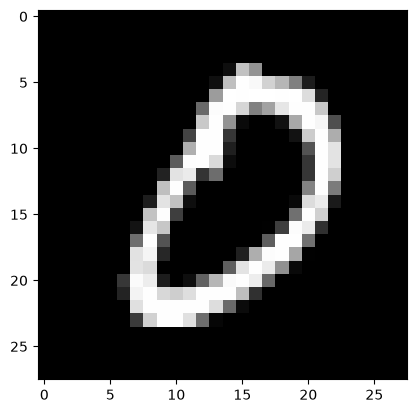

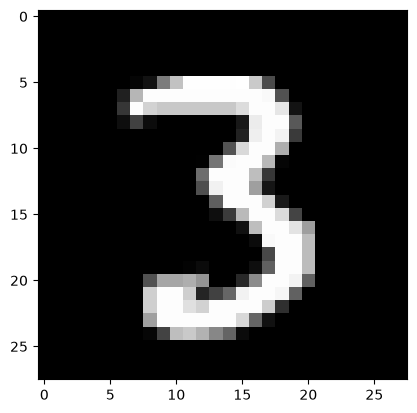

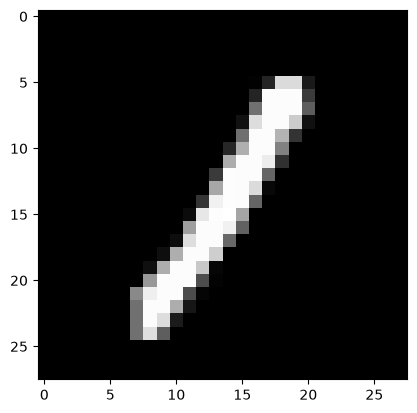

In [7]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

torch.manual_seed(0)

train_data = datasets.MNIST(root="./data", train=True, download=True)
test_data = datasets.MNIST(root="./data", train=False, download=True)

X_train = train_data.data.numpy()
y_train = train_data.targets.numpy()

X_test = test_data.data.numpy()
y_test = test_data.targets.numpy()

print(X_train.shape, X_train.dtype, y_train.shape)
print(X_test.shape, X_test.dtype, y_test.shape)

print(X_train[0].shape)

for i in range(3):
    plt.figure(), plt.imshow(X_train[np.random.randint(low=0, high=len(X_train)-1)], cmap='gray')

In [22]:
class MNISTVector(Dataset):
    def __init__(self, images, labels):
        self.images = images
        self.labels = labels

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        # (28, 28) uint8 -> (784,) float32 in [0, 1]; label -> int64
        x = torch.tensor(self.images[idx], dtype=torch.float32).flatten() / 255.0
        y = torch.tensor(self.labels[idx], dtype=torch.int64)
        return x, y


train_dataset = MNISTVector(X_train, y_train)
test_dataset = MNISTVector(X_test, y_test)

train_loader = DataLoader(train_dataset, batch_size=50, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=50, shuffle=False)

for X, y in train_loader:
    print(X.shape, y.shape)
    break

assert X.shape == (50, 784) and y.shape == (50,)
assert X.dtype == torch.float32 and y.dtype == torch.int64
assert X.min() >= 0 and X.max() <= 1

torch.Size([50, 784]) torch.Size([50])


**Hint**:

`torch.from_numpy(...)` / `tensor.float()`

`tensor.view(-1)` / `tensor.flatten()`

Pixelii sunt de tip `uint8`, cu valori în [0, 255].

`nn.CrossEntropyLoss` așteaptă label-uri de tip `torch.long`.

### 2. Rețea complet conectată (MLP)
Implementați o rețea simplă pentru a procesa imaginile vectorizate.
- Rețeaua trebuie să conțină doar straturi complet conectate (`nn.Linear(...)`).
- Rețeaua trebuie să conțină cel puțin 2 straturi (inclusiv ultimul).
- După ultimul strat nu urmează activare.
- După orice alt strat puteți să folosiți fie activare sigmoid (`F.sigmoid(...)`) sau tanh (`F.tanh(...)`) sau relu (`F.relu(...)`).
- Parametrii rețelei se scriu în constructor (`self.fc1 = nn.Linear(...)`).
- Parcurgerea rețelei se scrie în metoda `forward`.
- Intrarea rețelei este un tensor de dimensiunea (B, 784) unde B este batch_size și 784 reprezintă dimensiunea unui vector anterior calculat.
- Ieșirea rețelei este un tensor de dimensiune (B, 10) unde B este batch_size și 10 reprezintă numărul de clase.

In [24]:
class MLP(nn.Module):
    def __init__(self, in_features=784, hidden=128, n_classes=10, act=F.relu):
        super().__init__()
        self.act = act
        self.fc1 = nn.Linear(in_features=in_features, out_features=hidden)
        self.fc2 = nn.Linear(in_features=hidden, out_features=n_classes)
    
    def forward(self, x):
        x = self.act(self.fc1(x))   # (B, 784) -> (B, hidden), cu activare
        x = self.fc2(x)             # (B, hidden) -> (B, 10), fără activare
        return x


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = MLP().to(device)
print(device)
print(model)

for X, y in train_loader:
    X, y = X.to(device), y.to(device)
    y_pred = model(X)
    print(y_pred.shape)
    break

assert y_pred.shape == (X.shape[0], 10)
assert sum(isinstance(m, nn.Linear) for m in model.modules()) >= 2


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = MLP().to(device)
print(device)
print(model)

for X, y in train_loader:
    X, y = X.to(device), y.to(device)
    y_pred = model(X)
    print(y_pred.shape)
    break

assert y_pred.shape == (X.shape[0], 10)
assert sum(isinstance(m, nn.Linear) for m in model.modules()) >= 2

cuda
MLP(
  (fc1): Linear(in_features=784, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)
torch.Size([50, 10])
cuda
MLP(
  (fc1): Linear(in_features=784, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)
torch.Size([50, 10])


**Hint**:

`self.fc1 = nn.Linear(in_features, hidden)`, `self.fc2 = nn.Linear(hidden, n_classes)`

Păstrați activarea primită ca parametru (`self.act = act`) și aplicați-o în `forward` după fiecare strat, mai puțin ultimul.

Parametrii `in_features`, `hidden` și `act` sunt folosiți la ex. 3 și 6.

### 3. Antrenare
Antrenați modelul și observați rezultatele. Influențează funcțiile de activare rezultatele? Dar numărul de neuroni?

Funcția `test` se scrie la ex. 4, așa că aici bucla apelează doar `train`.

In [28]:
optimizer = torch.optim.SGD(model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()


def train(model, loader, optimizer):
    model.train()

    total_loss = 0
    total_correct = 0
    total_data = 0

    for X, y in loader:
        X, y = X.to(device), y.to(device)

        optimizer.zero_grad()

        out = model(X)
        loss = criterion(out, y)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

        total_correct += (out.argmax(dim=-1) == y).sum().item()
        total_data += y.size(0)

    return total_loss / len(loader), total_correct / total_data


epochs = 10
for epoch in range(epochs):
    train_loss, train_acc = train(model, train_loader, optimizer)
    print(f"Epoch {epoch}:")
    print(f"train loss={train_loss:.4f}, train acc={train_acc:.4f}")

Epoch 0:
train loss=0.0128, train acc=0.9968
Epoch 1:
train loss=0.0111, train acc=0.9976
Epoch 2:
train loss=0.0104, train acc=0.9979
Epoch 3:
train loss=0.0099, train acc=0.9981
Epoch 4:
train loss=0.0097, train acc=0.9982
Epoch 5:
train loss=0.0095, train acc=0.9983
Epoch 6:
train loss=0.0093, train acc=0.9983
Epoch 7:
train loss=0.0092, train acc=0.9984
Epoch 8:
train loss=0.0091, train acc=0.9984
Epoch 9:
train loss=0.0089, train acc=0.9985


Funcție ajutătoare, folosită și în exercițiile următoare: antrenează un număr fix de epoci și, dacă primește `test_loader`, afișează și metricile pe testare (cu `test` de la ex. 4).

In [26]:
def fit(model, train_loader, test_loader=None, epochs=10, optimizer=None, scheduler=None, verbose=True):
    model.to(device)
    if optimizer is None:
        optimizer = torch.optim.SGD(model.parameters(), lr=1e-3)

    for epoch in range(epochs):
        train_loss, train_acc = train(model, train_loader, optimizer)
        if scheduler is not None:
            scheduler.step()

        msg = f"Epoch {epoch}: train loss={train_loss:.4f}, acc={train_acc:.4f}"
        if test_loader is not None:  # reporting only, never used for training
            test_loss, test_acc = test(model, test_loader)
            msg += f" | test loss={test_loss:.4f}, acc={test_acc:.4f}"
        if verbose:
            print(msg)

    return train_loss, train_acc

In [29]:
exp_epochs = 5

activations = {"sigmoid": torch.sigmoid, "tanh": torch.tanh, "relu": F.relu}

for name, act in activations.items():
    torch.manual_seed(0)
    model = MLP(hidden=128, act=act)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    loss, acc = fit(model, train_loader, epochs=exp_epochs, optimizer=optimizer, verbose=False)
    print(f"act={name:<7} hidden=128 : train loss={loss:.4f}, acc={acc:.4f}")

for hidden in [16, 64, 256, 1024]:
    torch.manual_seed(0)
    model = MLP(hidden=hidden, act=F.relu)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    loss, acc = fit(model, train_loader, epochs=exp_epochs, optimizer=optimizer, verbose=False)
    print(f"act=relu    hidden={hidden:<4}: train loss={loss:.4f}, acc={acc:.4f}")

act=sigmoid hidden=128 : train loss=0.1093, acc=0.9686
act=tanh    hidden=128 : train loss=0.0624, acc=0.9823
act=relu    hidden=128 : train loss=0.0599, acc=0.9823
act=relu    hidden=16  : train loss=0.1960, acc=0.9435
act=relu    hidden=64  : train loss=0.0916, acc=0.9725
act=relu    hidden=256 : train loss=0.0424, acc=0.9872
act=relu    hidden=1024: train loss=0.0269, acc=0.9916


**Hint**:

`fit(MLP(hidden=..., act=...), train_loader, epochs=exp_epochs, verbose=False)` întoarce `(train_loss, train_acc)` de la ultima epocă.

**Observații**:

- Funcția de activare: ...
- Numărul de neuroni: ...

### 4. Evaluare pe datele de testare
Scrieți o funcție similară pentru a calcula funcția de cost și acuratețea pe datele de testare și apelați-o după pasul de antrenare.

In [ ]:
def test(model, loader):
    model.eval()

    total_loss = 0
    total_correct = 0
    total_data = 0

    with torch.no_grad():
        for X, y in loader:
            X, y = X.to(device), y.to(device)
            logits = model(X)
            loss = F.cross_entropy(logits, y)

            total_loss += loss.item()
            total_correct += (logits.argmax(dim=1) == y).sum().item()
            total_data += y.shape[0]

    return total_loss / len(loader), total_correct / total_data

In [31]:
torch.manual_seed(0)
model = MLP().to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=1e-3)

for epoch in range(epochs):
    train_loss, train_acc = train(model, train_loader, optimizer)
    test_loss, test_acc = test(model, test_loader)
    print(f"Epoch {epoch}:")
    print(f"train loss={train_loss:.4f}, train acc={train_acc:.4f}")
    print(f"test  loss={test_loss:.4f}, test  acc={test_acc:.4f}")

assert 0.5 < test_acc <= 1

Epoch 0:
train loss=2.1720, train acc=0.4303
test  loss=2.0201, test  acc=0.6267
Epoch 1:
train loss=1.8393, train acc=0.6872
test  loss=1.6311, test  acc=0.7361
Epoch 2:
train loss=1.4499, train acc=0.7521
test  loss=1.2523, test  acc=0.7864
Epoch 3:
train loss=1.1275, train acc=0.7926
test  loss=0.9841, test  acc=0.8173
Epoch 4:
train loss=0.9131, train acc=0.8203
test  loss=0.8141, test  acc=0.8360
Epoch 5:
train loss=0.7761, train acc=0.8374
test  loss=0.7040, test  acc=0.8476
Epoch 6:
train loss=0.6848, train acc=0.8477
test  loss=0.6287, test  acc=0.8584
Epoch 7:
train loss=0.6206, train acc=0.8566
test  loss=0.5741, test  acc=0.8656
Epoch 8:
train loss=0.5732, train acc=0.8632
test  loss=0.5334, test  acc=0.8719
Epoch 9:
train loss=0.5369, train acc=0.8686
test  loss=0.5011, test  acc=0.8776


**Hint**:

Aceeași buclă ca în `train`, dar fără `optimizer.zero_grad()`, `loss.backward()` și `optimizer.step()`.

`model.eval()` + `torch.no_grad()`: nu se calculează gradienți, iar Dropout / BatchNorm trec în modul de evaluare (contează la ex. 9).

### 5. Normalizare pe trăsături (medie 0, deviație 1)
Pentru datele de antrenare, înainte de a antrena rețeaua, calculați media și deviația pentru fiecare din cele 784 trăsături, după ce au fost scalate. Folosiți vectorii de medie și deviație pentru a normaliza datele în clasa `MNISTVector`. Țineți cont de faptul că datele de testare trebuie să parcurgă aceleași etape de preprocesare ca datele de antrenare.

In [37]:
X_train_scaled = torch.tensor(X_train, dtype=torch.float32).reshape(len(X_train), -1)

mean = X_train_scaled.mean(dim=0)
std = X_train_scaled.std(dim=0)

print(mean)
print(std)

tensor([0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        2.1000e-03, 7.8333e-03, 3.6000e-03, 1.5000e-04, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 2.6667e-04, 9.1667e-04, 9.2833e-03, 2.4283e-02,
        4.3717e-02, 6.4100e-02, 1.2013e-01, 1.6073e-01, 1.7418e-01, 1.7743e-01,
        1.8932e-01, 1.7415e-01, 1.8693e-01, 1.5365e-01, 1.0012e-01, 7.1233e-02,
        5.3817e-02, 2.1367e-02, 1.0083e-02, 3.5333e-03, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 1.0667e-03, 7.0000e-04,
        6.9500e-03, 5.4833e-03, 4.7100e-02, 1.3840e-01, 2.6418e-01, 5.0662e-01,
        8.6680e-01, 1.2901e+00, 1.8704e+00, 2.5299e+00, 3.2016e+00, 3.6256e+00,
        3.7220e+00, 3.3925e+00, 2.8029e+

### 6. PCA (100 de trăsături)
După normalizarea de la 5., pentru datele de antrenare aplicați PCA pentru a obține 100 de trăsături. Țineți cont de faptul că datele de testare trebuie să parcurgă aceleași etape de preprocesare ca datele de antrenare.

In [38]:
X_train_scaled = torch.tensor(X_train, dtype=torch.float32).reshape(len(X_train), -1)
mean = X_train_scaled.mean(dim=0)
std = X_train_scaled.std(dim=0)
X_train_norm = (X_train_scaled - mean) / std

n = X_train_norm.shape[0]
K = (X_train_norm.T @ X_train_norm).double() / (n - 1)

D, V = torch.linalg.eigh(K)
idx = torch.argsort(D, descending=True)
D, V = D[idx], V[:, idx]

V100 = V[:, :100].float()

### 7. PCA cu albire
Aplicați PCA cu albire pentru a obține 100 de trăsături.

### 8. Conexiune peste straturi (skip connection)
Antrenați o rețea cu cel puțin 2 straturi ascunse în care rezultatul primului strat ascuns contribuie la un strat mai avansat decât exact următorul.

In [ ]:
...

### 9. Regularizare
Adăugați straturi de regularizare (`nn.Dropout(...)` sau `nn.BatchNorm1d(...)`) și antrenați rețeaua.

In [ ]:
...

### 10. Cel puțin 98% acuratețe cu cel mult 1M de parametri
Fără a folosi deloc datele de testare în procesul de antrenare, antrenați un model cu cel mult 1 milion de parametri antrenabili compus doar din straturi complet conectate care obține o acuratețe de cel puțin 98% pe datele de testare.

In [ ]:
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)